In [1]:
import sys
sys.path.insert(0, '../code')

## Star catalog

In [4]:
from catalog import CatalogDownloader

cd = CatalogDownloader(catalog_name="Hatt2023")
tabs = cd.get_tables_from_vizier(row_limit=-1, save=True)

2025-12-19 14:23:06.018 | INFO     | catalog:__init__:1290 - Using Vizier key: J/A+A/669/A67
2025-12-19 14:23:06.020 | INFO     | catalog:get_tables_from_vizier:1327 - Downloading all tables from J/A+A/669/A67
2025-12-19 14:23:08.890 | INFO     | catalog:save_tables:1361 - Saved: /ut2/jerome/github/research/project/wakai/data/Hatt2023/Hatt2023_tab0.txt


{'J/A+A/669/A67/catalog': 'Solar-like oscillators catalog'}


In [8]:
df = tabs[0].to_pandas()
df

,TIC,NSectors,RP,PE,numax,e_numax,dnu,e_dnu,sample,Flag,Simbad,_RA,_DE
0,270536913,1,1,1,368.239990,11.22,24.170000,0.35,120-sec,,Simbad,324.77548,-33.67885
1,286507416,3,1,1,238.419998,2.17,17.930000,0.08,120-sec,,Simbad,185.80787,-67.63155
2,271701447,4,1,1,28.320000,0.00,4.050000,0.51,120-sec,,Simbad,187.13998,-56.40782
3,142275448,2,1,0,523.650024,14.99,32.049999,0.25,120-sec,,Simbad,40.53518,-46.52444
4,181655818,2,1,1,427.369995,6.99,26.510000,0.25,120-sec,,Simbad,13.74910,-74.30235
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172,149930673,4,1,0,17.129999,0.91,2.230000,0.06,20-sec,,Simbad,89.56057,-62.75499
4173,167720983,12,1,0,18.459999,0.49,2.670000,0.02,20-sec,,Simbad,103.30328,-64.04927
4174,177119085,11,0,1,32.470001,3.45,4.130000,0.05,20-sec,,Simbad,104.21043,-67.22735
4175,231091547,12,1,0,53.400002,2.43,5.130000,0.03,20-sec,,Simbad,68.83862,-68.22919


In [10]:
df.TIC.isin([460950389]).sum()

0

https://ui.adsabs.harvard.edu/abs/2024arXiv240302489H/abstract
* https://github.com/danhey/tess-atl/tree/main/catalog

In [11]:
import pandas as pd

df = pd.read_csv('https://github.com/danhey/tess-atl/raw/refs/heads/main/catalog/targets_120s.csv')
df

,TICID,Camera,CCD,Tmag,RA,Dec,sector
0,8195886,1,1,9.85,311.3326,-38.4275,1
1,8196058,1,1,8.18,311.3688,-38.0655,1
2,8196173,1,1,8.99,311.4127,-37.8439,1
3,8196285,1,1,9.08,311.3560,-37.5918,1
4,8196324,1,1,9.39,311.3043,-37.5068,1
...,...,...,...,...,...,...,...
1350469,10000551382,1,2,11.26,206.3297,41.7123,77
1350470,10001223313,1,1,17.08,233.8709,39.3796,77
1350471,10001331746,1,2,15.48,211.2612,47.1297,77
1350472,10001363713,2,1,14.83,245.4377,54.4567,77


In [13]:
df.TICID.isin([460950389]).sum()

2

In [14]:
dfs = []
for i in range(4):
    fp=f"https://github.com/danhey/tess-atl/raw/refs/heads/main/catalog/atl_{i}.csv"
    d = pd.read_csv(fp)
    dfs.append(d)

In [15]:
dfs = pd.concat(dfs)
dfs.shape

(1588789, 14)

In [18]:
dfs.dr3_source_id.isin([5239758155778687360]).sum()

1

In [19]:
dfs.query("dr3_source_id==5239758155778687360")

,ID,ra,dec,dr3_source_id,Tmag,atl_radius,atl_teff,atl_logg,numax,p_120,p_20,p_120_1s,p_20_1s,Sectors
317601,460950389,159.158146,-64.798275,5239758155778687360,11.649,0.8203,4716.540527,4.4992,3919.202876,0.050102,0.050229,0.050042,0.050094,6


## LiEW catalog

In [2]:
from catalog import CatalogDownloader

cd = CatalogDownloader(catalog_name="Gutierrez-Albarran2024", catalog_type="LiEW")
tabs = cd.get_tables_from_vizier(row_limit=-1, add_cols='e_EWcLi')

2025-12-19 13:41:23.867 | INFO     | catalog:__init__:1290 - Using Vizier key: J/A+A/685/A83
2025-12-19 13:41:23.869 | INFO     | catalog:get_tables_from_vizier:1327 - Downloading all tables from J/A+A/685/A83


{'J/A+A/685/A83/clusters': 'List of studied clusters',
 'J/A+A/685/A83/tablec1': 'GES parameters',
 'J/A+A/685/A83/tablec2': 'Gaia parameters and Prot',
 'J/A+A/685/A83/tablec3': 'Membership analysis criteria and final cluster '
                          'selections'}


In [3]:
df_cluster = tabs[0].to_pandas()
df_cluster.columns

Index(['Cluster', 'Name', 'RAJ2000', 'DEJ2000', 'N'], dtype='object')

In [85]:
df_cluster

,Cluster,Name,RAJ2000,DEJ2000,N
0,1,NGC 6530,18 04 31.00,-24 21 30.0,1937
1,2,Rho Oph,16 25 35.11,-23 26 49.8,311
2,3,Trumpler 14,10 43 56.64,-59 33 10.8,1368
3,4,Cha I,11 06 47.99,-77 17 59.9,709
4,5,NGC 2244,06 32 10.79,+04 54 50.3,432
5,6,NGC 2264,06 40 52.07,+09 52 37.2,1857
6,7,Lambda Ori,05 35 08.27,+09 56 02.9,836
7,8,Col 197,08 44 48.48,-41 16 48.0,409
8,9,Gamma Vel,08 09 31.95,-47 20 11.7,1269
9,10,NGC 2232,06 27 33.12,-04 44 56.3,1838


In [11]:
df_cluster.query("Name=='IC 2602'")

,Cluster,Name,RAJ2000,DEJ2000,N
12,13,IC 2602,10 42 27.11,-64 25 33.6,1831


In [12]:
df_liew = tabs[1].to_pandas()
df_liew.columns

Index(['No', 'CNAME', 'RAJ2000', 'DEJ2000', 'RV', 'l_vsini', 'vsini', 'Teff',
       'TeffIRFM', 'logg', 'gamma', '__Fe_H_', 'l_EWcLi', 'EWcLi', 'f_EWcLi',
       'l_EWLiunv', 'EWLiunv', 'f_EWLiunv', 'l_Li1', 'Li1', 'f_Li1', 'n_Li1',
       'EWHaAcc', 'Ha10', 'EWHachr', 'GID', 'GSize', 'e_EWcLi'],
      dtype='object')

In [13]:
df_liew.EWcLi.dropna().shape

(17072,)

In [14]:
df_ic2602=df_liew[df_liew.No==13]
df_ic2602.dropna(subset='EWcLi').shape #Blends-corrected Li

(1584, 28)

<ErrorbarContainer object of 3 artists>

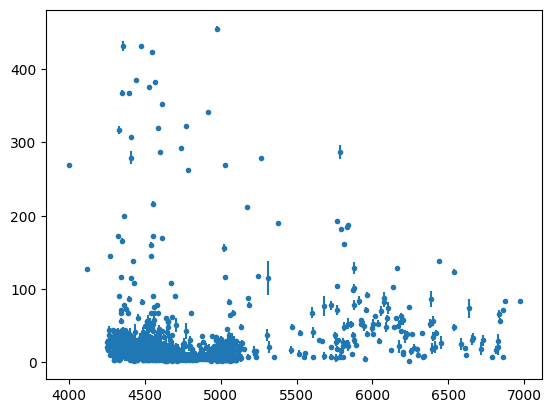

In [15]:
import matplotlib.pyplot as pl

df_ic2602 = df_ic2602.dropna(subset=['Teff','EWcLi','e_EWcLi'])
pl.errorbar(df_ic2602['Teff'], df_ic2602['EWcLi'], yerr=df_ic2602['e_EWcLi'], ls='', marker='.')

## cluster catalog

In [1]:
import pandas as pd

df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)

,Name(s),name,N_50,r_50,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,pmRA,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,305.52488,37.23809,75.66132,0.15836,0.5007,-2.4023,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.25,n
18265,XDOCC 11,xdocc11,54.0,4.3,317.73684,47.70377,89.41856,-0.28394,0.4536,-1.0068,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.09,n
18266,Zanin 6,zanin6,24.0,39.4,342.91235,41.33289,99.92967,-16.14552,2.6838,5.9365,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.08,y
18267,Zeta Gemini,zetagemini,19.0,8.0,105.96593,20.56051,195.72326,11.87995,0.2679,-0.7368,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.09,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,103.73696,-5.89465,218.61444,-1.85052,3.4866,-7.4140,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [2]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101181101717965312,104.13589,-5.48616,3.4796,0.0468,-7.6025,0.0414,-2.4144,0.0409,NaN,NaN,218.39623,-1.36721,15.6225,2.8157,0.0029,0.0131,1.000
1095682,zhbjz1,3100956320310482048,104.53184,-5.89465,3.5259,0.0222,-7.7372,0.0278,-2.5817,0.0294,16.6076,5.3441,218.93959,-1.20291,14.2556,1.7210,0.0031,0.0085,1.000
1095683,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095684,zhbjz1,3101094072800870400,103.15896,-5.98809,3.6033,0.1457,-7.2640,0.1371,-2.6682,0.1321,NaN,NaN,218.40071,-2.46118,17.4554,3.3142,0.0032,0.0574,0.921
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [3]:
df_mem.columns

Index(['name', 'Source', 'RA_ICRS', 'DE_ICRS', 'Plx', 'e_Plx', 'pmRA',
       'e_pmRA', 'pmDE', 'e_pmDE', 'RV', 'e_RV', 'GLON', 'GLAT', 'Gmag',
       'BP-RP', 'e_Gmag', 'e_BP-RP', 'probs'],
      dtype='object')

In [4]:
df_mem_ic2602 = df_mem.query("name=='melotte102'")
df_mem_ic2602.shape

(0, 19)

In [65]:
from astropy.coordinates import SkyCoord

c1 = SkyCoord(df_ic2602.RAJ2000.values, df_ic2602.DEJ2000.values, unit=('hourangle','deg'))
c2 = SkyCoord(df_mem_ic2602.RA_ICRS.values, df_mem_ic2602.DE_ICRS.values, unit='deg')

In [66]:
import numpy as np

def crossmatch_catalogs(c1, c2, max_sep_arcsec=None):
    """
    Crossmatch two SkyCoord lists.

    Parameters
    ----------
    c1 : SkyCoord
        First coordinate list.
    c2 : SkyCoord
        Second coordinate list.
    max_sep_arcsec : float or None
        Maximum separation allowed for accepting a match.
        If None, all nearest neighbors are returned.

    Returns
    -------
    idx : ndarray
        Indices in c2 corresponding to each entry in c1.
    sep : Quantity
        Angular separations for each match.
    mask : ndarray (boolean)
        True where matched within max_sep_arcsec.
    """
    idx, sep2d, _ = c1.match_to_catalog_sky(c2)

    if max_sep_arcsec is not None:
        limit = max_sep_arcsec * u.arcsec
        mask = sep2d < limit
    else:
        mask = np.ones(len(c1), dtype=bool)

    return idx, sep2d, mask

In [73]:
idx, sep, mask = crossmatch_catalogs(c1, c2, max_sep_arcsec=3)
df_ic2602["match_idx"] = idx
df_ic2602["sep_arcsec"] = sep.to(u.arcsec).value
df_ic2602["matched"] = mask

In [77]:
idx = df_ic2602.matched==True
df_ic2602[idx].head()

,No,CNAME,RAJ2000,DEJ2000,RV,l_vsini,vsini,Teff,TeffIRFM,logg,...,Ha10,EWHachr,GID,GSize,e_EWcLi,ra,dec,match_idx,sep_arcsec,matched
11889,13,10284372-6435392,10 28 43.72,-64 35 39.2,18.600000,<,11.000000,6858,<NA>,4.07,...,NaN,0.16,<NA>,<NA>,1,10 28 43.72,-64 35 39.2,143,0.541127,True
12056,13,10314490-6329221,10 31 44.90,-63 29 22.1,NaN,,NaN,6969,<NA>,4.08,...,NaN,NaN,<NA>,<NA>,1,10 31 44.90,-63 29 22.1,270,0.357988,True
12083,13,10334181-6413457,10 33 41.81,-64 13 45.7,16.700001,,9.100000,5177,<NA>,4.30,...,92.699997,1.32,<NA>,<NA>,1,10 33 41.81,-64 13 45.7,221,0.372401,True
12201,13,10381766-6408065,10 38 17.66,-64 08 06.5,17.200001,,19.299999,5832,<NA>,4.41,...,NaN,0.22,<NA>,<NA>,1,10 38 17.66,-64 08 06.5,471,0.356797,True
12279,13,10395597-6359300,10 39 55.97,-63 59 30.0,14.800000,,47.700001,4774,<NA>,NaN,...,167.940002,2.22,<NA>,<NA>,2,10 39 55.97,-63 59 30.0,472,0.272422,True


/tmp/ipykernel_1270141/1491212462.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_ic2602 = df_ic2602[idx].dropna(subset=['Teff','EWcLi','e_EWcLi'])


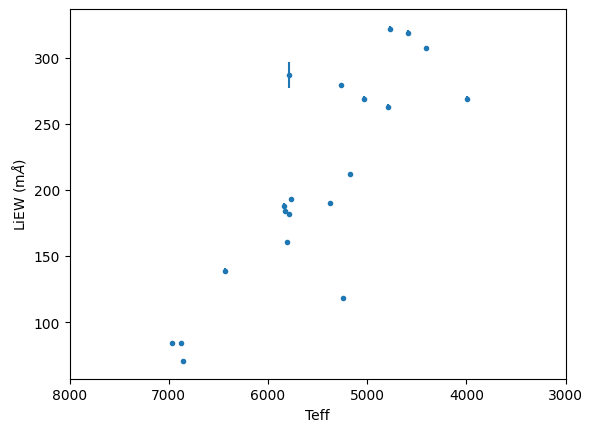

In [86]:
import matplotlib.pyplot as pl

df_ic2602 = df_ic2602[idx].dropna(subset=['Teff','EWcLi','e_EWcLi'])
fig, ax = pl.subplots()
ax.errorbar(df_ic2602['Teff'], df_ic2602['EWcLi'], yerr=df_ic2602['e_EWcLi'], ls='', marker='.')
ax.set_xlabel('Teff (K)')
ax.set_xlim(8000,3000)
ax.set_ylabel(r'LiEW (m$\AA$)');